In [1]:
import matlab.engine

In [2]:
eng = matlab.engine.start_matlab()

In [3]:
s = eng.genpath("/home/kushal/repos/NMFLibrary/")
eng.addpath(s, nargout=0)

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from clustering.utils import generate_data

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD Radeon Graphics (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 22.3.6
❗ limited,"llvmpipe (LLVM 15.0.6, 256 bits)",CPU,Vulkan,Mesa 22.3.6 (LLVM 15.0.6)
❌,"AMD Radeon Graphics (gfx1103_r1, LLVM 15.0.6, DRM 3.49, 6.1.0-28-amd64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [5]:
%matplotlib inline

In [6]:
from pathlib import Path
import os
import tifffile
from skophys.preprocessing import Vectorizer, UnVectorizer, PercentileFilter

/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [7]:
import pandas as pd
from data_lib.data_lib import config, SeriesAccessor, DataFrameAccessor

In [8]:
from numba import njit, prange

In [9]:
config.set_parent_path("/home/kushal/repos/td-svd-sandbox/data_lib/")

In [10]:
df = pd.read_csv("./data_lib/data/dataframe.csv")

In [11]:
movie_path = Path("./vaz_rect-2_z-0_mcorr.tif")

In [12]:
movie = tifffile.memmap(movie_path)[:, 250:400:2, ::2]

In [13]:
df.lib.add_item(
    name="vaz-1-subsample",
    movie=movie,
    rect=1,
    kind="soma-cortex",
    source="flynn-rockefeller",
    orig=None,
)

In [14]:
df

,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,name,rect,kind,source,orig,symm_nmf,uuid
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,caiman-demo,NaN,soma,caiman,NaN,NaN,ca0d0779-4d51-44d8-8396-c3323422ff5b
1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,dendrites-1,1.0,dendrites,jason,NaN,NaN,70b87e26-ef67-40b5-97aa-1e2b710927ce
2,2.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,NaN,cortex-dendrites,1.0,crazy,andrea-tolias,NaN,NaN,4d827dd4-f18f-4eb7-95e9-7e3ad23544b6
3,3.0,3.0,3.0,3.0,3.0,3.0,3.0,NaN,NaN,NaN,cortex-dendrites,2.0,crazy,andrea-tolias,NaN,NaN,ffdd40c5-6fce-4218-9b3f-d5836ac89464
4,4.0,4.0,4.0,4.0,4.0,4.0,4.0,NaN,NaN,NaN,cortex-dendrites,3.0,crazy,andrea-tolias,NaN,NaN,99ec6c6f-8cd0-4eca-a7b3-8a20edb0e8eb
5,5.0,5.0,5.0,5.0,5.0,NaN,NaN,NaN,NaN,NaN,sue-movie,NaN,soma,caiman,NaN,NaN,2762373e-ca08-469f-a04f-f9ed9e9b80e2
6,6.0,6.0,6.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,drg,1.0,drg,drg-person,NaN,NaN,659dab9d-18f8-40b8-aae4-91fb0b6332a1
7,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,drg-gaussian-derivative,1.0,drg,drg-person,NaN,NaN,f1c2e96e-61de-4d86-bf71-e1118f8803d5
8,8.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,vaz-1,1.0,soma-cortex,flynn-rockefeller,NaN,NaN,e1e70b61-beb6-463a-b09f-635791eab650
9,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,vaz-1-subsample,1.0,soma-cortex,flynn-rockefeller,NaN,NaN,ebccff3e-314a-45f7-9e33-77ff3d0df6db


In [327]:
ix = -1

In [328]:
uid = df.iloc[ix]["uuid"]

In [329]:
movie = df.iloc[ix].lib.load_movie()

In [330]:
movie.shape

(1730, 75, 70)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
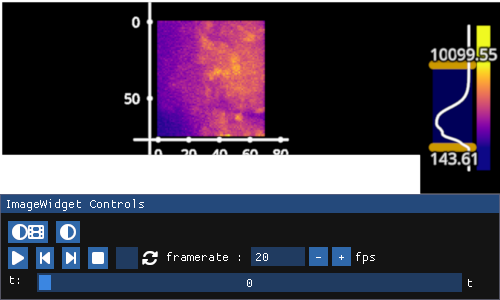

In [331]:
fpl.ImageWidget(movie).show()

In [332]:
unvec = UnVectorizer(shape=movie.shape[1:])

In [333]:
Y = Vectorizer().transform(movie)

In [334]:
Y = PercentileFilter(window_size=5, quantile=10).transform(Y)

In [335]:
Y.shape

(5250, 1730)

In [336]:
Y = Y[:, :-50:5].copy()

In [337]:
Y.shape

(5250, 336)

RFBOutputContext()

JupyterWgpuCanvas(css_height='500px', css_width='700px')
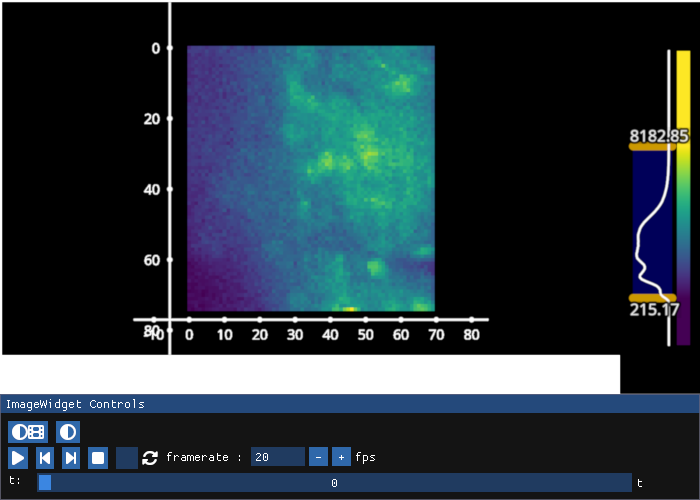

In [338]:
iw_series = fpl.ImageWidget(
    unvec.transform(Y),
    cmap="viridis",
    figure_kwargs={"size": (700, 500)},
)
# iw_series.figure[0, 0].camera.maintain_aspect = False
iw_series.show()

In [339]:
Y_s = (Y - Y.mean(axis=1)[:, None]) / Y.std(axis=1)[:, None]

RFBOutputContext()

JupyterWgpuCanvas(css_height='500px', css_width='700px')
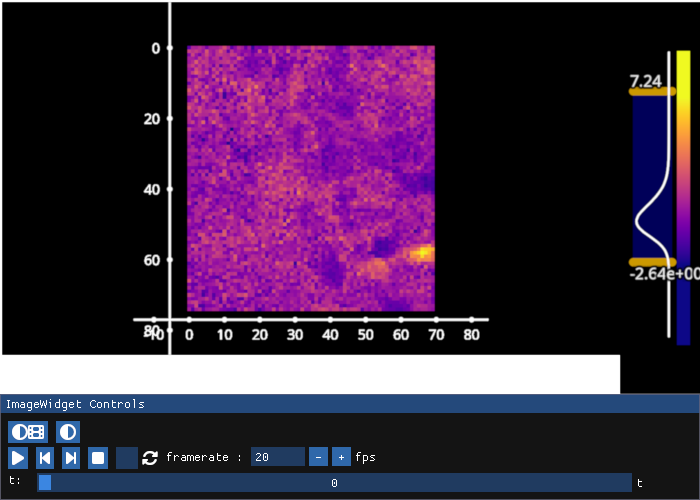

In [340]:
iw_series = fpl.ImageWidget(
    unvec.transform(Y_s),
    figure_kwargs={"size": (700, 500)},
)
# iw_series.figure[0, 0].camera.maintain_aspect = False
iw_series.show()

In [311]:
iw_series.window_funcs = {"t": (np.mean, 11)}

In [312]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [341]:
@njit(parallel=True)
def get_distances_ortho(
    i: int,
    Y: np.ndarray,
    projections: np.ndarray,
    dists: np.ndarray,
):
    # thres = np.percentile(Y, 95)
    for j in prange(Y.shape[0]):
        u = Y[i]
        v = Y[j]

        high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

        u = u[high_val_ixs]
        v = v[high_val_ixs]

        # u += u.mean()
        # v += v.mean()

        X = np.zeros((u.size, 2))
        X[:, 0] = u
        X[:, 1] = v

        U, S, Vt = np.linalg.svd(X, full_matrices=False)
        v1 = Vt[0, :]

        projections_pre = (X @ v1)
        
        projections[j, :u.size, 0] = projections_pre * v1[0]
        projections[j, :u.size, 1] = projections_pre * v1[1]

        orthogonal_distances = np.abs(X - projections[j, :u.size])  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)

        dists[j] = s / u.size

In [224]:
@njit(parallel=True)
def get_distances_lr(
    i: int,
    Y: np.ndarray,
    projections: np.ndarray,
    dist_reg: np.ndarray,
):
    for j in prange(Y.shape[0]):
        u = Y[i]
        v = Y[j]
        
        high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

        u = u[high_val_ixs]
        v = v[high_val_ixs]
        
        i_dot_j = np.dot(u, v)
        i_dot_i = np.dot(u, u)
        
        m = (i_dot_j - 1 / high_val_ixs.sum() * u.sum() * v.sum()) / (i_dot_i - 1 / high_val_ixs.sum() * u.sum()**2)
        
        v1 = np.array([m, 1])

        u_mean = np.mean(u)
        v_mean = np.mean(v)
        
        v1[0] += u_mean
        v1[1] += v_mean

        denom = np.sqrt(v1.sum())
        v1[0] = v1[0] / denom
        v1[1] = v1[1] / denom

        v1 /= np.sqrt(np.sum(v1**2))
        
        X = np.zeros((u.size, 2))
        X[:, 0] = u
        X[:, 1] = v
        
        projections_pre = (X @ v1)

        projections = np.zeros((u.size, 2))
        
        projections[:, 0] = projections_pre * v1[0]
        projections[:, 1] = projections_pre * v1[1]

        orthogonal_distances = X - projections  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)
            
        dist_reg[j] = s

In [237]:
projections = np.zeros((*Y.shape, 2))
output_matrix = np.zeros((Y.shape[0],))
get_distances_ortho(
    523,
    Y_s,
    projections,
    output_matrix,
)

Text(0.5, 1.0, 'D: sum of orthogonal distances to regression line')

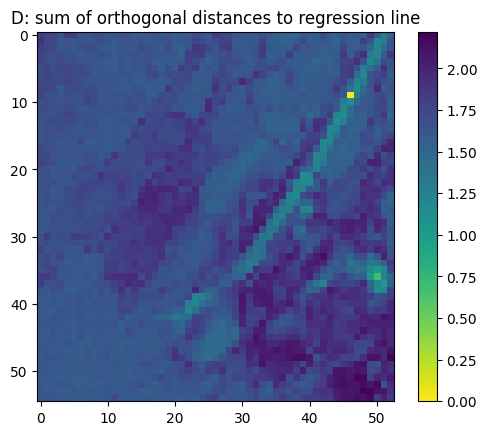

In [238]:
plt.imshow(unvec.transform(output_matrix), cmap="viridis_r")
plt.colorbar()
plt.title("D: sum of orthogonal distances to regression line")

Text(0.5, 1.0, '$D^2$')

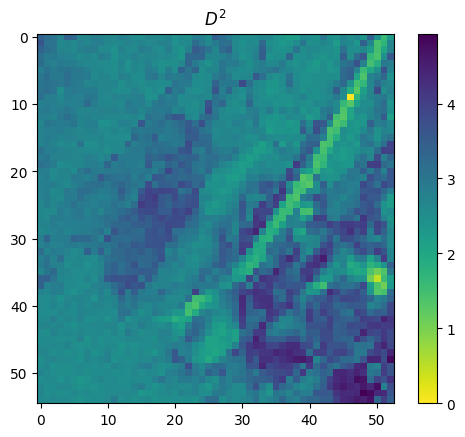

In [239]:
plt.imshow(unvec.transform(output_matrix**2), cmap="viridis_r")
plt.colorbar()
plt.title("$D^2$")

In [31]:
from scipy.ndimage import gaussian_filter1d

In [314]:
@njit(parallel=True)
def get_corr(
    i: int,
    Y: np.ndarray,
    dists: np.ndarray,
):
    for j in prange(Y.shape[0]):
        u = Y[i]
        v = Y[j]

        # high_val_ixs = (u > np.percentile(u, 75)) | (vmovie[:, ::2, ::2] > np.percentile(v, 75))

        # u = u[high_val_ixs]
        # v = v[high_val_ixs]

        # u -= u.mean()
        # v -= v.mean()

        corr = (u.T @ v) / (np.linalg.norm(u, ord=2) * np.linalg.norm(v, ord=2))

        corr = max(corr, 0)

        dists[j] = corr

In [33]:
Y_gd = gaussian_filter1d(Y_s, sigma=8, axis=1, order=1)

In [40]:
output_corr = np.zeros((Y.shape[0],))
get_corr(
    1308,
    Y_gd,
    output_corr,
)

In [41]:
np.ravel_multi_index((18, 48), unvec.shape)

np.int64(1308)

Text(0.5, 1.0, '$u^Tv$ with top percentile')

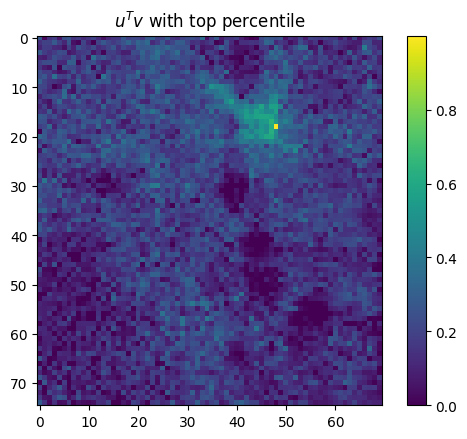

In [42]:
plt.imshow(unvec.transform(output_corr))
plt.colorbar()
plt.title("$u^Tv$ with top percentile")

Text(0.5, 1.0, '$(u^Tv)^2$ with top percentile')

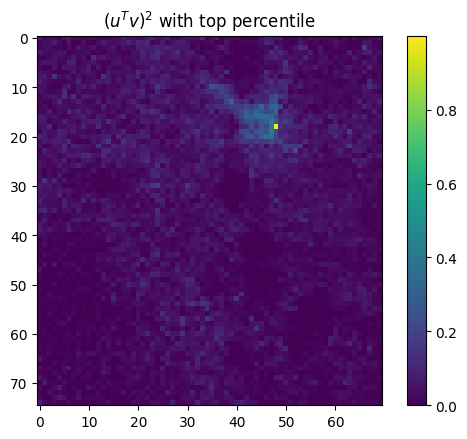

In [43]:
plt.imshow(unvec.transform(output_corr**2))
plt.colorbar()
plt.title("$(u^Tv)^2$ with top percentile")

In [44]:
output_corr.min()

np.float64(0.0)

In [315]:
dist_cov = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float32)

In [316]:
from tqdm import tqdm

In [317]:
for i in tqdm(range(Y.shape[0])):
    projections = np.zeros((*Y.shape, 2))
    output_matrix = np.zeros((Y.shape[0],))
    get_distances_ortho(
        i,
        Y_s,
        projections,
        output_matrix,
    )
    dist_cov[i] = output_matrix

100%|██████████████████████████████████████████████████████████████████████████| 5250/5250 [00:45<00:00, 115.20it/s]


In [231]:
from ipywidgets import VBox, HBox

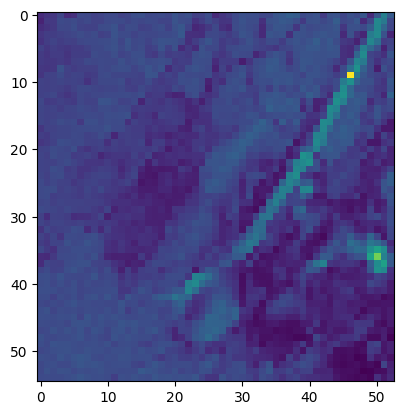

In [268]:
lam = 0.15e1

A = np.exp(-dist_cov**2 / lam**2)
img = unvec.transform(A[523])
plt.imshow(img)

In [269]:
A.min(), A.max()

(np.float32(0.06649088), np.float32(1.0))

In [270]:
lam = 0.15e1

A = np.exp(-dist_cov**2 / lam**2)
img = unvec.transform(A[0])

W = np.asarray(eng.symm_anls(A, 3.0)["W"])

figure_kwargs = {
    "shape" : (1, 3),
    "controller_ids": [[0, 0, 1]],
    "size": (1600, 580),
}
iw_matrices = fpl.ImageWidget(
    [dist_cov, A, img], 
    names=["Distance matrix", "Affinity", "row of A"], 
    cmap="viridis",
    histogram_widget=False,
    figure_kwargs=figure_kwargs,
)

vals, edges = np.histogram(dist_cov.ravel(), bins=100)
cdf = np.column_stack([edges[1:], np.log10(np.cumsum(vals[::-1]))])

fig_cdf = fpl.Figure(names=[["cdf(D)"]], size=(1600, 640))
cdf_g = fig_cdf[0, 0].add_line(cdf)

cdf_selector = cdf_g.add_linear_selector()
cdf_selector.selection = lam

affinity_row_selector = iw_matrices.managed_graphics[1].add_linear_selector(axis="y")


@cdf_selector.add_event_handler("selection")
def update_lam(ev):
    lam = ev.graphic.selection
    global A
    A = np.exp(-dist_cov**2 / lam**2)
    iw_matrices.managed_graphics[1].data = A
    iw_matrices.managed_graphics[2].data = unvec.transform(A[affinity_row_selector.get_selected_index()])


@affinity_row_selector.add_event_handler("selection")
def udpate_affinity_row(ev):
    index = ev.get_selected_index()
    global A
    img = unvec.transform(A[index])
    iw_matrices.managed_graphics[2].data = img


@iw_matrices.managed_graphics[2].add_event_handler("double_click")
def update_affinity_row_click(ev):
    col, row = ev.pick_info["index"]

    index = np.ravel_multi_index((row, col), unvec.shape)
    affinity_row_selector.selection = index

VBox([iw_matrices.show(), fig_cdf.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()

In [271]:
dist_cov.max()

np.float32(2.4696262)

In [272]:
dist_cov.min()

np.float32(0.0)

In [274]:
dist_cov -= dist_cov.max()
dist_cov = np.abs(dist_cov)

In [275]:
dist_cov.min()

np.float32(0.0)

In [318]:
snmf_results = eng.symm_anls(dist_cov, 32.0)

In [319]:
W = np.asarray(snmf_results["W"])
H = np.asarray(snmf_results["H"])

In [320]:
W.shape, H.shape

((5250, 32), (32, 5250))

In [321]:
np.linalg.norm(W - H.T, ord="fro")

np.float64(0.0)

RFBOutputContext()

JupyterWgpuCanvas(css_height='1700px', css_width='1300px')
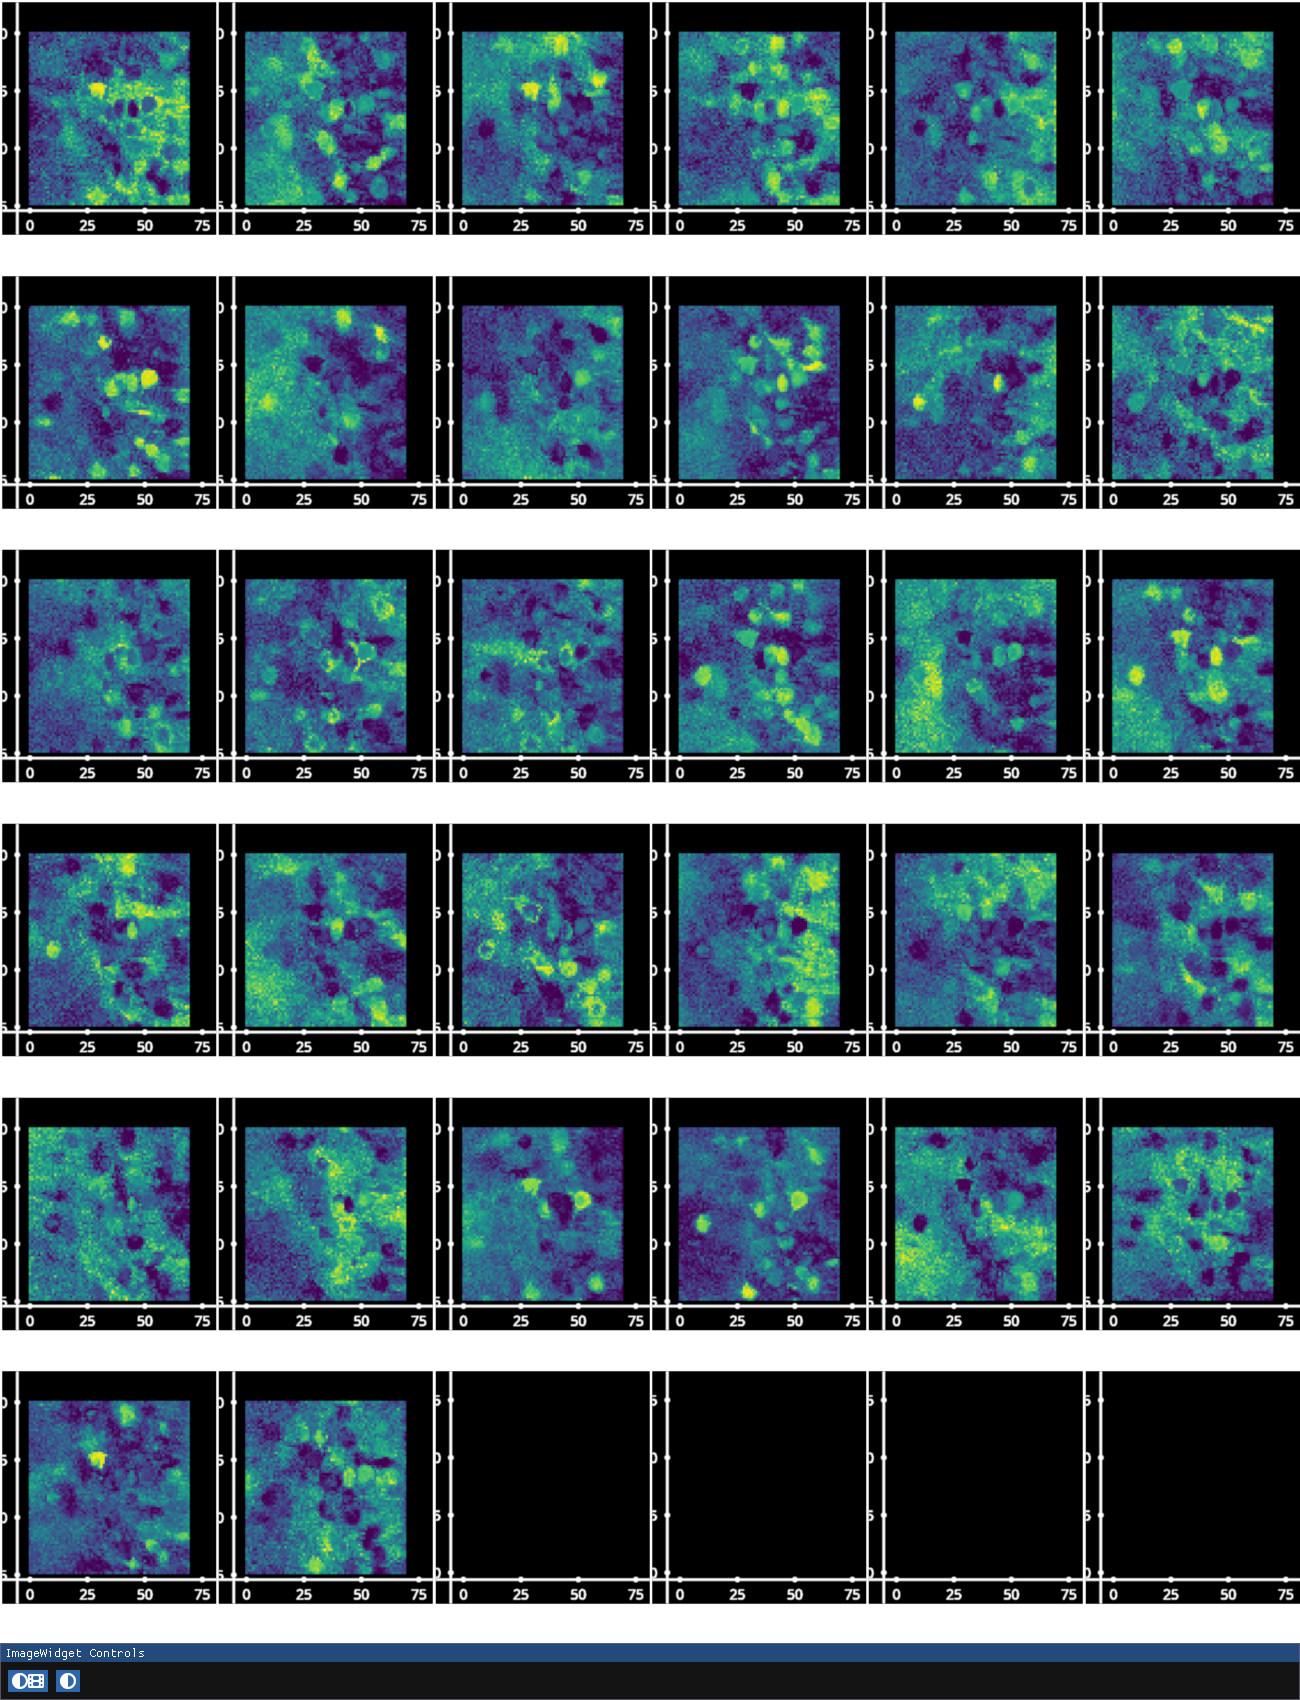

In [322]:
iw_s = fpl.ImageWidget([a for a in unvec.transform(W)], cmap="viridis", histogram_widget=False, figure_kwargs={"size": (1300, 1700)})
iw_s.show()

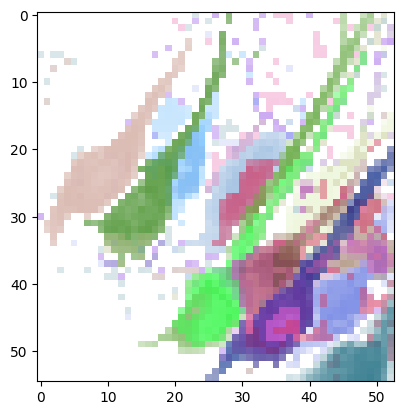

In [293]:
for a in unvec.transform(W):
    c = np.zeros((*a.shape, 4))
    rows, cols = np.where(a > np.percentile(a, 95))
    c[rows, cols, :-1] = np.random.rand(3)
    c[rows, cols, -1] = a[rows, cols]
    plt.imshow(c)

In [ ]:
for sp in iw_s.figure:
    sp.toolbar = False
    sp.axes.visible = False
    sp.camera.zoom = 0.98

In [323]:
os.makedirs(config.PARENT_PATH.joinpath(uid, "symm_nmf"))

In [324]:
A = np.empty((0))

In [325]:
for arr, n in zip([dist_cov, A, W, H], ["D", "A", "W", "H"]):
    np.save(config.PARENT_PATH.joinpath(uid, "symm_nmf", f"{n}.npy"), arr)

In [326]:
for g in iw_s.managed_graphics:
    g.vmin = np.percentile(g.data[:], 90)